# Modelling Stock Price Movements with Stochastic Processes

**Stocks:** Apple (AAPL), JPMorgan Chase (JPM), Coca-Cola (KO)
**Models:** Geometric Brownian Motion (GBM), Ornstein-Uhlenbeck on log price (OU), Merton jump-diffusion

## README - how to run

| Step | Command |
|---|---|
| Install dependencies | `pip install -r requirements.txt` |
| Run this notebook | open it in Jupyter / VS Code / Colab and *Run All* |
| Or run the pipeline as a script | `python run_analysis.py` (add `--source yfinance` for fresh Yahoo Finance data, `--n-paths 5000` for more simulations) |
| Rebuild the PDF report | `python build_report.py` |

**Files**

* `stochastic_models.py` - data cleaning, diagnostics, the three models (calibration + simulation), risk metrics, backtest and plotting functions.
* `run_analysis.py` - the end-to-end pipeline; writes `figures/` and `results/`.
* `data/kaggle_sp500_AAPL_JPM_KO.csv` - daily prices for the three stocks, extracted from the Kaggle *S&P 500 stock data* dataset (Nugent, 2018), 8 Feb 2013 - 7 Feb 2018. It is bundled so the analysis runs offline and is exactly reproducible.

All randomness is seeded (`SEED = 42`), so re-running gives identical numbers.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import stochastic_models as sm
import run_analysis as cfg

sm.set_plot_style()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)

## 1. Data collection and preprocessing

`load_prices_kaggle` reads the long-format Kaggle file and pivots it to one close-price column per ticker.
`clean_prices` then sorts by date, removes duplicate dates, treats non-positive prices as missing,
forward-fills gaps of up to three days, drops incomplete rows, and **flags** (without deleting)
returns whose robust z-score exceeds 6. Large equity moves are usually real news, and they are
exactly what the jump model has to learn from.

In [2]:
raw = sm.load_prices_kaggle(cfg.KAGGLE_CSV, cfg.TICKERS)
prices, cleaning_report = sm.clean_prices(raw)
print({k: v for k, v in cleaning_report.items() if k != "flagged_returns"})
print("Flagged large moves:", cleaning_report["flagged_returns"])
prices.tail()

{'rows_in': 1259, 'duplicate_dates_removed': 0, 'non_positive_prices': 0, 'missing_before_fill': 0, 'rows_dropped_incomplete': 0, 'rows_out': 1259, 'start': '2013-02-08', 'end': '2018-02-07'}
Flagged large moves: {'AAPL': [('2014-01-28', -0.0833), ('2014-04-24', 0.0788), ('2016-01-27', -0.068)], 'JPM': [('2016-02-12', 0.08), ('2016-06-24', -0.072)], 'KO': [('2013-04-16', 0.0553), ('2014-10-21', -0.0622), ('2014-10-29', 0.0422), ('2016-04-20', -0.049)]}


Name,AAPL,JPM,KO
date,,,
2018-02-01,167.78,116.87,47.45
2018-02-02,160.50,114.28,46.73
2018-02-05,156.49,108.80,44.89
2018-02-06,163.03,112.11,44.67
2018-02-07,159.54,112.87,44.56


In [3]:
calib = prices.iloc[-(cfg.CALIBRATION_DAYS + 1):]   # last two years used for calibration
returns = sm.log_returns(prices)
ax = sm.plot_price_history(prices, calib.index[0])
ax.set_title("Daily closing prices, rebased to 100");

## 2. Diagnostics that motivate the model choice

* **Jarque-Bera** p-values near zero and large excess kurtosis -> returns are fat-tailed, which a pure GBM cannot produce; this motivates the **jump-diffusion**.
* **ADF** test on log price: a low p-value would support **mean reversion (OU)**; a high p-value means we cannot reject a random walk (**GBM**).
* **Ljung-Box on squared returns**: a low p-value signals volatility clustering, a feature none of the three models has (a limitation).

In [4]:
diag = pd.DataFrame({t: sm.diagnostics(calib[t]) for t in cfg.TICKERS}).T
diag[["ann_drift_log", "ann_vol", "skew", "excess_kurtosis", "jb_pvalue",
      "adf_pvalue", "half_life_days", "ljungbox_sq_ret_p", "max_drawdown"]]

,ann_drift_log,ann_vol,skew,excess_kurtosis,jb_pvalue,adf_pvalue,half_life_days,ljungbox_sq_ret_p,max_drawdown
AAPL,0.2592,0.1981,0.2613,5.0908,3.7478e-120,0.7093,236.9094,8.7013e-01,-0.1941
JPM,0.3456,0.2000,0.1739,6.9507,1.3756e-221,0.8438,345.5057,2.3285e-05,-0.1246
KO,0.0219,0.1235,-1.3468,6.1137,2.9425e-204,0.2146,38.0015,3.2280e-01,-0.1433


In [5]:
sm.plot_return_diagnostics(returns.loc[calib.index[1]:]);

## 3. Models

| Model | SDE | Calibration |
|---|---|---|
| GBM | $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$ | MLE from log returns |
| OU (log price) | $dX_t = \kappa(\theta - X_t)\,dt + \sigma\,dW_t,\; X_t = \ln S_t$ | OLS on the exact AR(1) discretisation |
| Merton | $dS_t/S_{t^-} = (\mu - \lambda k)\,dt + \sigma\,dW_t + (J-1)\,dN_t,\; \ln J \sim N(\mu_J, \sigma_J^2)$ | MLE of the Poisson mixture of normals |

All three are simulated with their **exact** transition laws, so there is no time-discretisation error.
Below, each model is calibrated on the last two years of AAPL and simulated once as a demonstration.

In [6]:
rng = np.random.default_rng(cfg.SEED)
s0 = float(prices["AAPL"].iloc[-1])
demo = {}
for name, model in sm.make_models().items():
    model.fit(calib["AAPL"])
    print(f"{name:7s}", {k: round(v, 4) for k, v in model.params().items()})
    demo[name] = model.simulate(s0, 180, cfg.N_PATHS, rng)
sm.plot_fan_charts(demo, "AAPL (demo, x-axis in trading days)");

GBM     {'mu': 0.2788, 'sigma': 0.1981}
OU      {'kappa': 0.7373, 'theta_price': 182.6827, 'sigma': 0.1984, 'half_life_days': 236.9094}


Merton  {'mu': 0.2674, 'sigma': 0.153, 'lam': 12.0, 'mu_j': 0.003, 'sigma_j': 0.0322, 'total_vol': 0.1895}


## 4. Full Monte Carlo study, risk metrics and backtest

`run_analysis.main()` repeats the steps above for every stock and model with 1,000 paths each over
30, 60 and 180 trading days, computes the risk metrics, runs a GBM drift-sensitivity check and the
rolling-origin backtest (70 forecast origins per stock), and saves every figure and table.
It takes about 1-2 minutes.

In [7]:
cfg.main([])

Data: 2013-02-08 to 2018-02-07, 1259 trading days


Backtest AAPL: 70 origins


Backtest JPM: 70 origins


Backtest KO: 70 origins


      n_obs  ann_drift_log  ann_vol    skew  excess_kurtosis  jb_pvalue  adf_stat  adf_pvalue  ar1_coef  half_life_days  ljungbox_ret_p  ljungbox_sq_ret_p  \
AAPL  504.0         0.2592   0.1981  0.2613           5.0908        0.0   -1.1144      0.7093    0.9971        236.9094          0.1424             0.8701   
JPM   504.0         0.3456   0.2000  0.1739           6.9507        0.0   -0.7114      0.8438    0.9980        345.5057          0.9556             0.0000   
KO    504.0         0.0219   0.1235 -1.3468           6.1137        0.0   -2.1773      0.2146    0.9819         38.0015          0.8672             0.3228   

      max_drawdown  
AAPL       -0.1941  
JPM        -0.1246  
KO         -0.1433  
  ticker   model      mu   sigma   kappa  theta_price  half_life_days   lam    mu_j  sigma_j  total_vol
0   AAPL     GBM  0.2788  0.1981     NaN          NaN             NaN   NaN     NaN      NaN        NaN
1   AAPL      OU     NaN  0.1984  0.7373     182.6827        236.9094   NaN

In [8]:
params = pd.read_csv("results/model_parameters.csv")
params

,ticker,model,mu,sigma,kappa,theta_price,half_life_days,lam,mu_j,sigma_j,total_vol
0,AAPL,GBM,0.2788,0.1981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AAPL,OU,NaN,0.1984,0.7373,182.6827,236.9094,NaN,NaN,NaN,NaN
2,AAPL,Merton,0.2674,0.1530,NaN,NaN,NaN,12.0,0.0030,0.0322,0.1895
3,JPM,GBM,0.3656,0.2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,JPM,OU,NaN,0.2003,0.5056,158.3135,345.5057,NaN,NaN,NaN,NaN
5,JPM,Merton,0.3393,0.1396,NaN,NaN,NaN,12.0,0.0039,0.0336,0.1823
6,KO,GBM,0.0295,0.1235,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,KO,OU,NaN,0.1241,4.5965,44.3415,38.0015,NaN,NaN,NaN,NaN
8,KO,Merton,0.0846,0.0922,NaN,NaN,NaN,12.0,-0.0133,0.0156,0.1164


In [9]:
metrics = pd.read_csv("results/forecast_risk_metrics.csv")
metrics.pivot_table(index=["ticker", "horizon_days"], columns="model",
                    values=["median", "prob_loss", "var_95", "es_95"]).round(3)

es_95                 median                   prob_loss               var_95              
model                  GBM Merton     OU      GBM   Merton       OU       GBM Merton     OU    GBM Merton     OU
ticker horizon_days                                                                                             
AAPL   30            0.102  0.099  0.114  164.436  164.203  161.494     0.326  0.315  0.420  0.079  0.070  0.086
       60            0.129  0.105  0.134  169.348  169.125  163.587     0.277  0.260  0.392  0.092  0.074  0.104
       180           0.146  0.148  0.182  192.355  190.574  168.993     0.147  0.125  0.327  0.092  0.088  0.141
JPM    30            0.094  0.098  0.107  117.764  116.749  115.051     0.276  0.264  0.375  0.069  0.071  0.083
       60            0.103  0.116  0.134  122.536  121.795  117.401     0.194  0.198  0.328  0.073  0.066  0.101
       180           0.068  0.110  0.158  145.888  141.966  126.081     0.055  0.082  0.199  0.002  0.030  0.112
KO     30            0.081  0.077  0.070   44.603   45.154   44.464     0.487  0.389  0.523  0.065  0.057  0.056
       60            0.108  0.100  0.083   44.743   45.338   44.361     0.478  0.376  0.543  0.089  0.078  0.067
       180           0.177  0.145  0.088   45.137   47.354   44.395     0.453  0.282  0.542  0.146  0.101  0.072

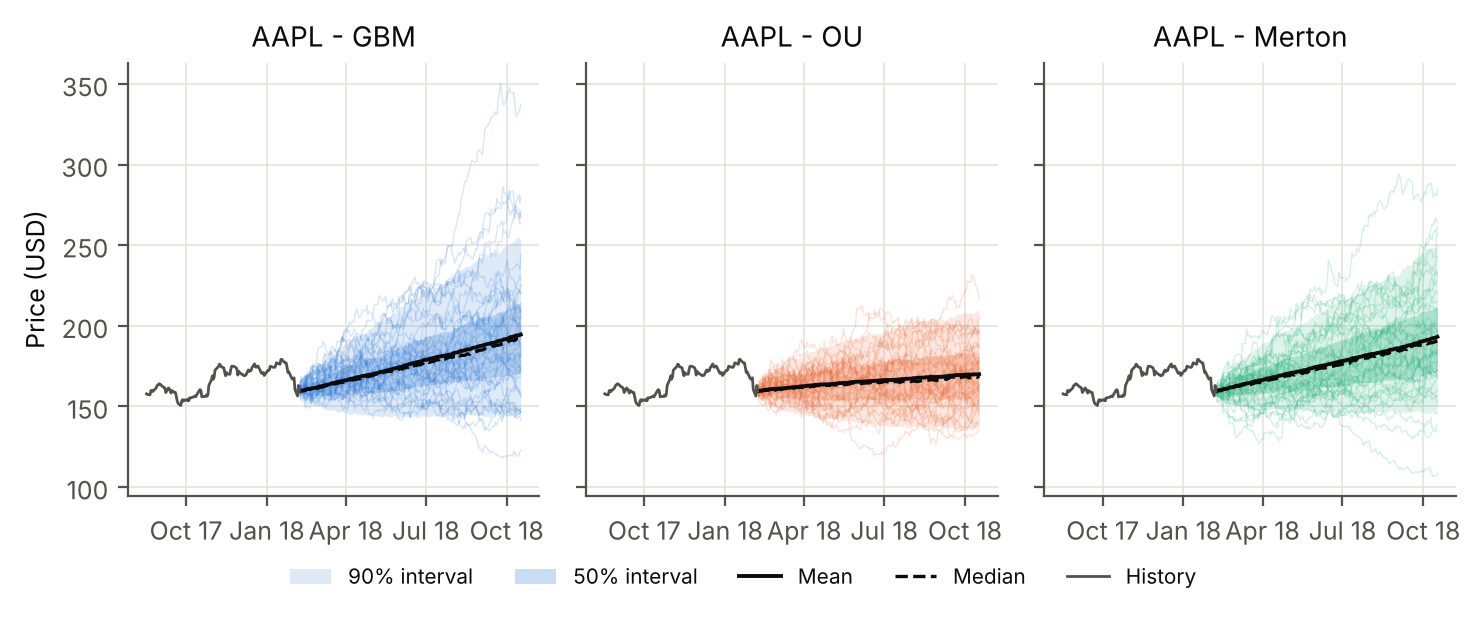

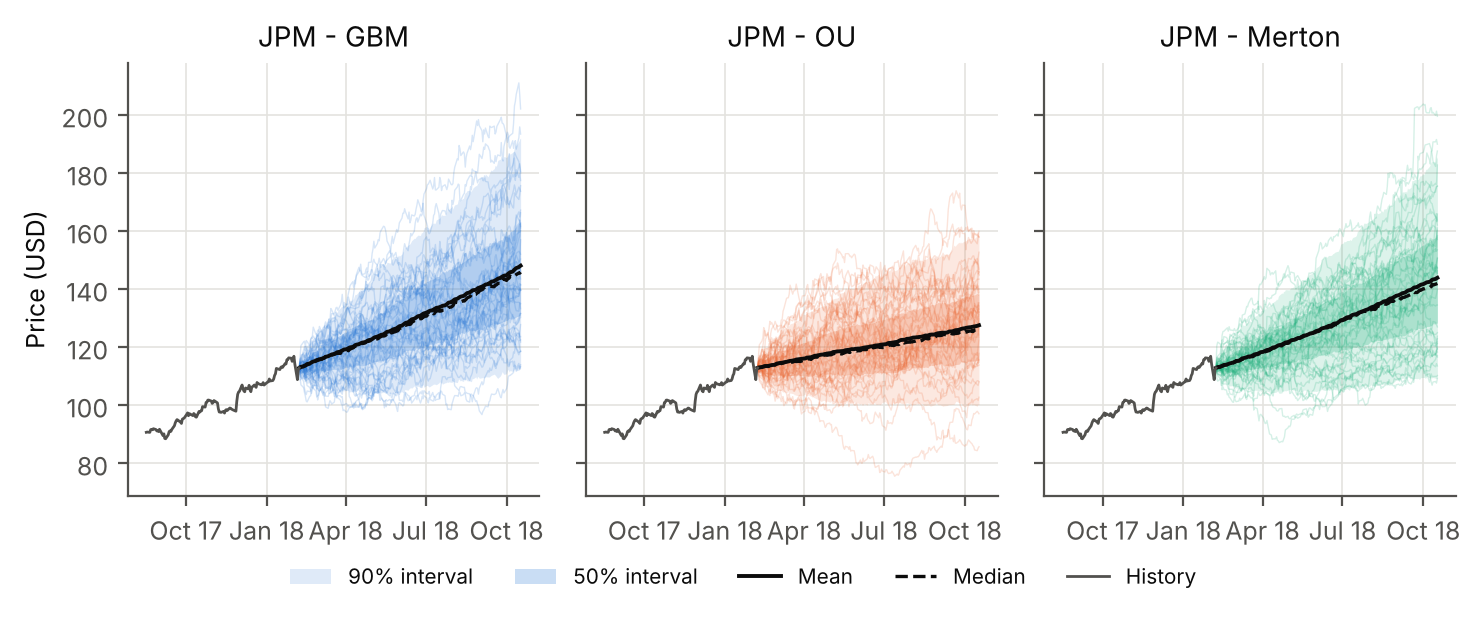

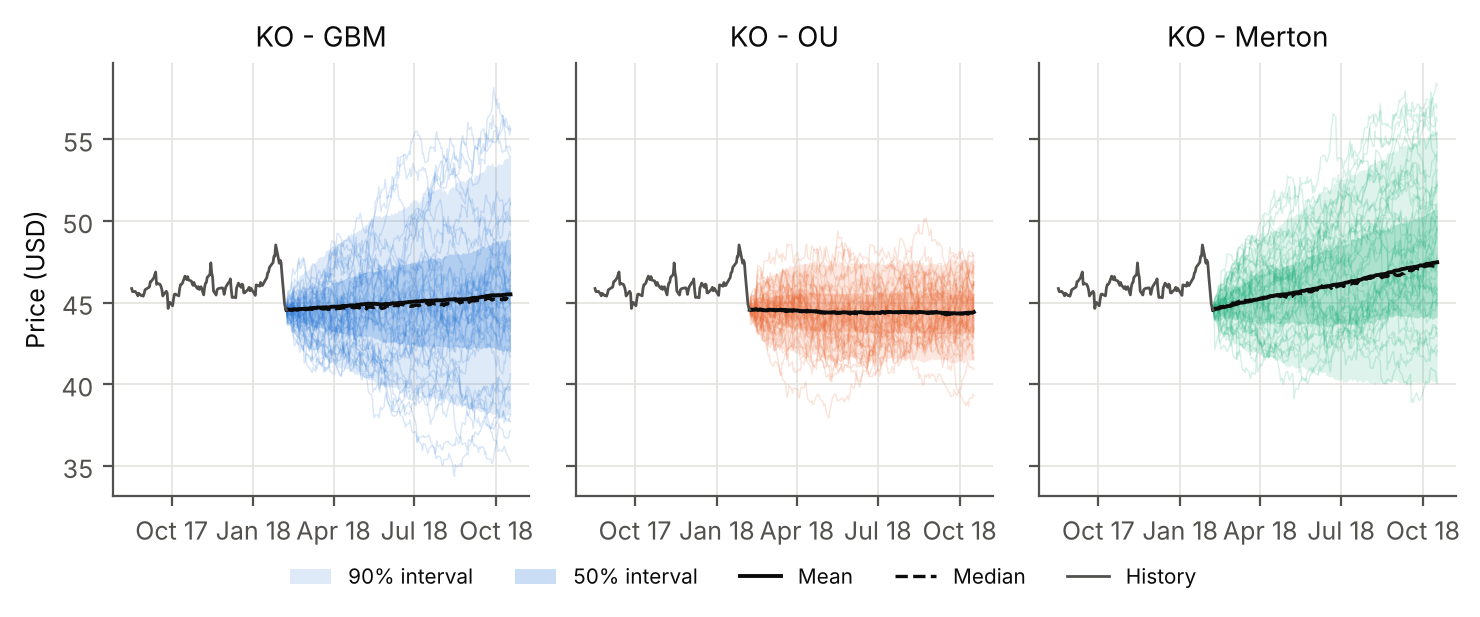

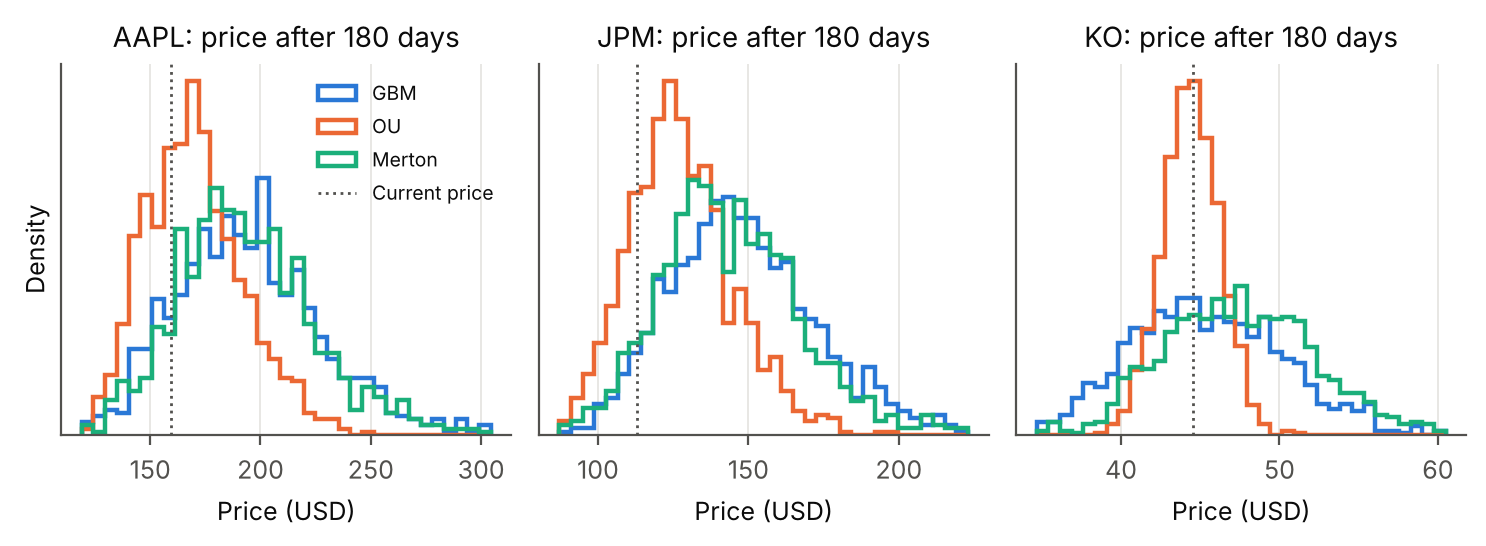

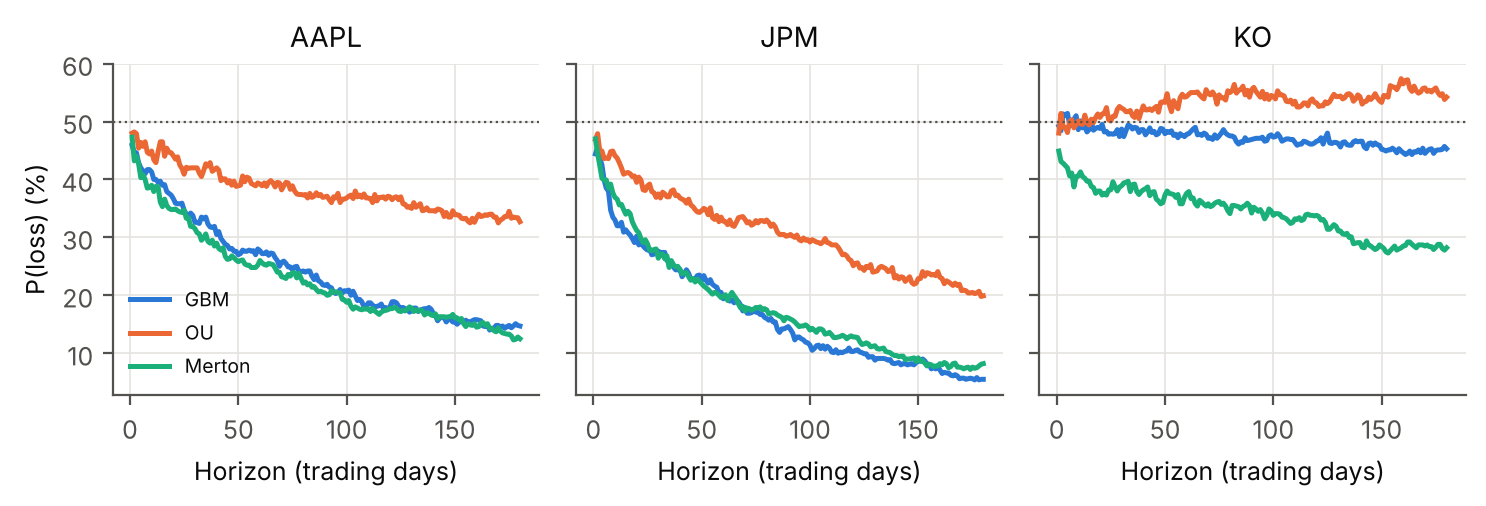

In [10]:
for f in ["fig3_fan_AAPL", "fig3_fan_JPM", "fig3_fan_KO",
          "fig4_terminal_distributions", "fig5_probability_of_loss"]:
    display(Image(f"figures/{f}.png", width=820))

### Drift sensitivity

The historical drift is the least reliable input: a two-year sample cannot pin down an expected return.
GBM is re-simulated with the same volatility and three drifts.

In [11]:
pd.read_csv("results/gbm_drift_sensitivity.csv")[
    ["ticker", "drift", "mu", "median", "prob_loss", "prob_drop_10", "var_95", "es_95"]].round(3)

,ticker,drift,mu,median,prob_loss,prob_drop_10,var_95,es_95
0,AAPL,historical,0.279,192.999,0.129,0.040,0.088,0.148
1,AAPL,8% long-run,0.080,165.965,0.402,0.198,0.210,0.271
2,AAPL,zero,0.000,159.349,0.502,0.276,0.248,0.291
3,JPM,historical,0.366,143.001,0.059,0.020,0.013,0.098
4,JPM,8% long-run,0.080,118.130,0.395,0.193,0.200,0.264
5,JPM,zero,0.000,110.859,0.554,0.288,0.247,0.290
6,KO,historical,0.030,45.130,0.448,0.131,0.153,0.187
7,KO,8% long-run,0.080,46.954,0.293,0.062,0.119,0.156
8,KO,zero,0.000,44.249,0.528,0.168,0.161,0.198


### Out-of-sample backtest

At each origin, every model is calibrated only on the preceding two years and its forecast is scored
against the realised price. A well-calibrated model's 90% interval should contain the realised price
about 90% of the time; CRPS (lower is better) scores the whole forecast distribution; the Brier score
scores the predicted probability of a loss.

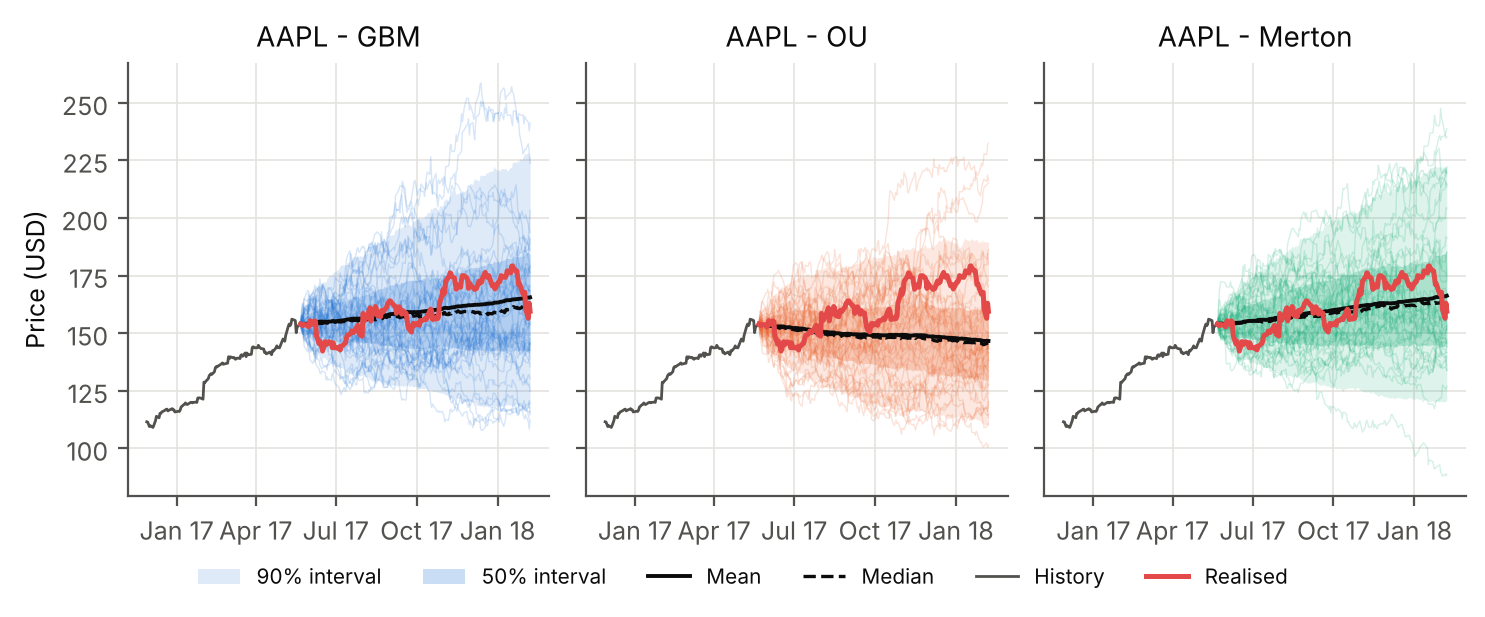

,ticker,model,horizon,origins,coverage_90,crps_pct,brier,median_abs_err_pct
0,AAPL,GBM,30,70,0.871,4.812,0.267,6.889
1,AAPL,GBM,60,70,0.871,7.198,0.291,10.008
2,AAPL,Merton,30,70,0.871,4.819,0.269,6.909
3,AAPL,Merton,60,70,0.857,7.174,0.287,10.054
4,AAPL,OU,30,70,0.843,4.711,0.256,6.633
5,AAPL,OU,60,70,0.786,6.830,0.300,9.303
6,JPM,GBM,30,70,0.900,4.009,0.228,5.272
7,JPM,GBM,60,70,0.900,5.977,0.222,7.907
8,JPM,Merton,30,70,0.900,3.961,0.223,5.242
9,JPM,Merton,60,70,0.871,5.948,0.218,7.921


In [12]:
display(Image("figures/fig6_backtest_example.png", width=820))
pd.read_csv("results/backtest_summary.csv").round(3)

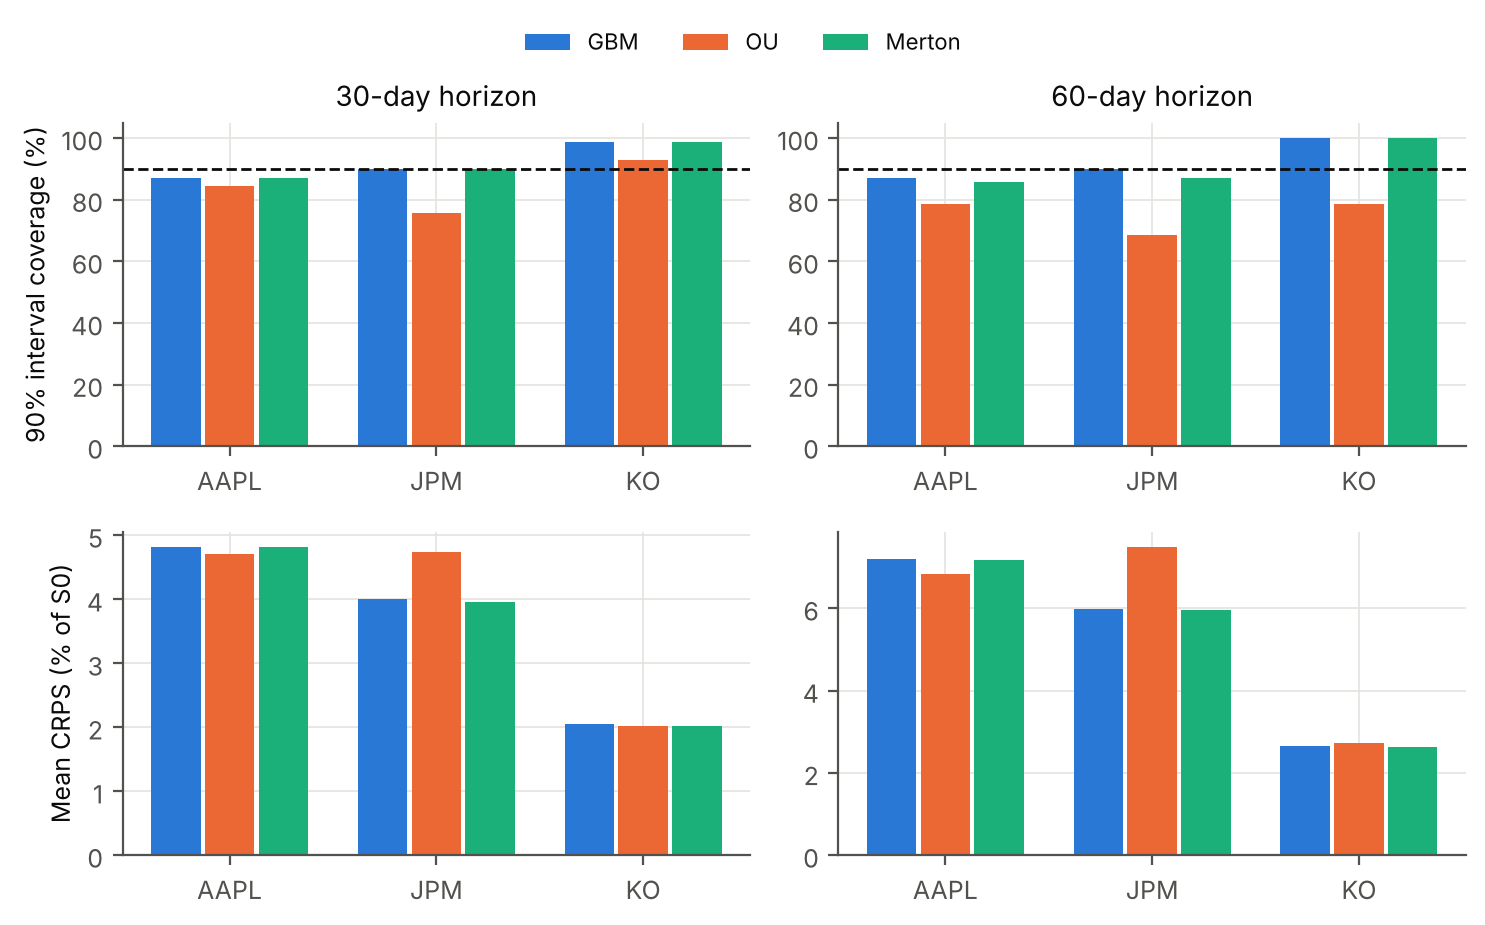

In [13]:
display(Image("figures/fig7_backtest_summary.png", width=820))

## 5. Key takeaways

* **GBM and Merton** produce well-calibrated 30/60-day intervals for AAPL and JPM (coverage 86-90% for a nominal 90%); for KO they are too wide (99-100%) because KO was calmer after calibration than during it.
* **OU** intervals are too narrow (coverage down to 69% for JPM): the ADF test cannot reject a unit root, so the fitted mean reversion is mostly an artefact of the sample and the model is overconfident.
* **Merton** adds a large likelihood improvement and fatter tails at short horizons, but its forecast scores are almost identical to GBM's: over 30+ days the jumps average out.
* **Drift dominates long-horizon risk**: AAPL's 180-day probability of loss moves from about 13% (historical drift) to about 40% (8% drift). Short-horizon risk (VaR, ES) depends mostly on volatility and is far more robust.

See `Stochastic_Stock_Price_Modeling_Report.pdf` for the full discussion and recommendations.